# Phase 1 & Phase 2: Data Analysis, Cleaning, & Visualization

This notebook covers the initial loading, inspection, cleaning, outlier analysis, and exploratory data visualization of the Telco Customer Churn dataset.

## Objectives:
1. **Phase 1 — Data Cleaning:** Identify and resolve datatype anomalies (`TotalCharges` string conversion, check `SeniorCitizen`), check missing values (empirical verification of `tenure == 0` for NaNs), remove duplicates, and analyze outliers.
2. **Phase 2 — Exploratory Visualization:** Plot univariate, bivariate, and multivariate relationships to understand drivers of churn, saving plots to `reports/figures/` and documenting business takeaways.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for plots
sns.set_theme(style="whitegrid")
sns.set_palette("muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

## 1. Load and Inspect the Dataset

In [2]:
# Load the dataset
data_path = os.path.join("..", "data", "raw", "WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(data_path)

# Inspect shape and first few rows
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Inspect column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Initial Observations:
1. **`TotalCharges` Gotcha:** The column `TotalCharges` is read as an `object` (string) even though it represents a currency amount. This is a common data quality issue where blank spaces or character markers hide inside a numeric column, preventing pandas from parsing it as float.
2. **`SeniorCitizen` Inconsistency:** `SeniorCitizen` is represented as an integer (`0` and `1`), whereas all other binary categorical columns (like `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `Churn`) are represented as `'Yes'` and `'No'` strings. We must note this difference for our Phase 3 encoding step.

In [4]:
# Verify SeniorCitizen value distribution
print("SeniorCitizen unique values:")
print(df["SeniorCitizen"].value_counts(dropna=False))
print(f"\nSeniorCitizen Data Type: {df['SeniorCitizen'].dtype}")

SeniorCitizen unique values:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

SeniorCitizen Data Type: int64


## 2. Data Cleaning

### Step 2.1: Convert `TotalCharges` to Numeric
We will convert `TotalCharges` using `pd.to_numeric` with `errors='coerce'`. This will turn any non-numeric strings (like blank spaces) into `NaN` so we can identify and handle them.

In [5]:
# Convert TotalCharges and count NaNs
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
num_nans = df["TotalCharges"].isna().sum()
print(f"Number of NaNs generated in TotalCharges: {num_nans}")

Number of NaNs generated in TotalCharges: 11


### Step 2.2: Verify the NaN / `tenure == 0` Relationship
Let's empirically test if these missing values correspond *exclusively* to brand new customers (`tenure == 0`). If we assume this without checking, we could be misimputing data for long-term customers.

In [6]:
# Query the rows with NaN in TotalCharges
nan_rows = df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]
print(nan_rows)
print(f"\nAre all NaN TotalCharges rows associated with tenure == 0? {all(nan_rows['tenure'] == 0)}")

      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN

Are all NaN TotalCharges rows associated with tenure == 0? True


### Step 2.3: Impute Missing Values
**Justification for Imputation:** 
Since all 11 rows with missing `TotalCharges` correspond to new customers who have a `tenure` of 0 months, they haven't completed their first billing cycle. Their accumulated charge is indeed **0**. 

We will impute these NaNs with `0.0`. This is more mathematically and logically sound than dropping the rows (which would lose training data) or imputing them with the mean/median (which would falsely inflate their total charges).

In [7]:
# Impute missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
print(f"Missing values in TotalCharges after imputation: {df['TotalCharges'].isna().sum()}")

Missing values in TotalCharges after imputation: 0


### Step 2.4: Drop Identifier Column (`customerID`)
The `customerID` is a unique identifier. It has a cardinality of 7043 and has no predictive power. Keeping it would overcomplicate the model and potentially cause overfitting if the model tries to learn from it.

In [8]:
# Drop customerID
df = df.drop(columns=["customerID"])
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Step 2.5: Duplicate Check (Post-ID Drop)
If we checked for duplicates *before* dropping `customerID`, we wouldn't find any because `customerID` is unique for every row. Checking for duplicates **after** dropping `customerID` ensures we look for duplicate customers in the feature space.

In [9]:
# Check for duplicates in the remaining feature space
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows in feature space: {num_duplicates}")

if num_duplicates > 0:
    df = df.drop_duplicates()
    print(f"Duplicates removed. New dataset shape: {df.shape}")

Number of duplicate rows in feature space: 22
Duplicates removed. New dataset shape: (7021, 20)


### Step 2.6: Verification of Clean Data
We verify that the datatypes are correct and there are no nulls.

In [10]:
print(f"TotalCharges final data type: {df['TotalCharges'].dtype}")
print(f"Total missing values remaining in dataset: {df.isnull().sum().sum()}")

TotalCharges final data type: float64
Total missing values remaining in dataset: 0


## 3. Outlier Detection

We will check for outliers in our numerical columns: `tenure`, `MonthlyCharges`, and `TotalCharges`.

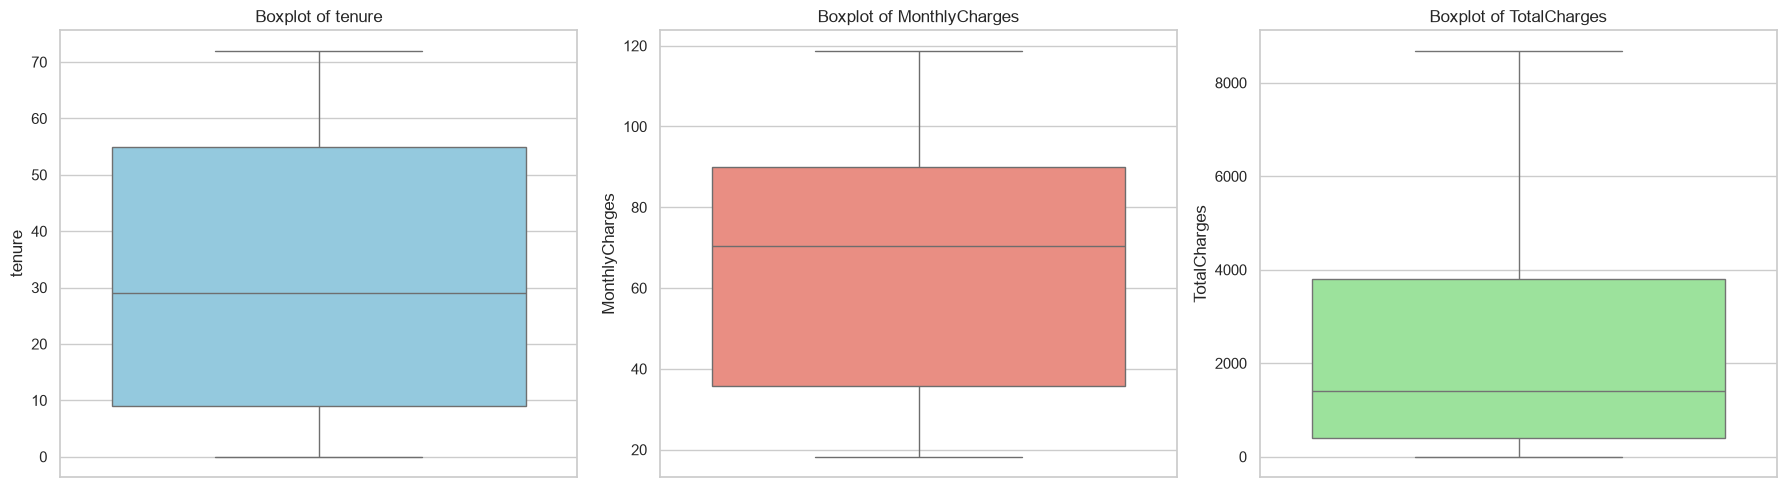

In [11]:
# Boxplots for numerical columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(y=df["tenure"], ax=axes[0], color="skyblue")
axes[0].set_title("Boxplot of tenure")

sns.boxplot(y=df["MonthlyCharges"], ax=axes[1], color="salmon")
axes[1].set_title("Boxplot of MonthlyCharges")

sns.boxplot(y=df["TotalCharges"], ax=axes[2], color="lightgreen")
axes[2].set_title("Boxplot of TotalCharges")

plt.tight_layout()
plt.show()

In [12]:
# IQR Outlier Detection function
def detect_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    return outliers, lower_bound, upper_bound

for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    outliers, lb, ub = detect_outliers_iqr(df, col)
    print(f"{col} IQR bounds: [{lb:.2f}, {ub:.2f}] | Number of flagged outliers: {len(outliers)}")

tenure IQR bounds: [-60.00, 124.00] | Number of flagged outliers: 0
MonthlyCharges IQR bounds: [-45.48, 171.12] | Number of flagged outliers: 0
TotalCharges IQR bounds: [-4694.17, 8899.22] | Number of flagged outliers: 0


### Outlier Interpretation (Interview Talking Points):

1. **Statistical Outlier Flagging:** Using the IQR method implemented in this project, no observations in `tenure` and `MonthlyCharges` were flagged as statistical outliers. 
2. **Why Outliers Aren't Anomaly-Based:** Even if some extreme values were flagged (such as very high `TotalCharges` or `MonthlyCharges`), they would represent **real, high-value customer accounts** rather than errors (like negative numbers or impossible inputs). Falsely removing them would eliminate critical signals of high-spending accounts that are valuable targets for churn retention.
3. **Structural Correlation of `TotalCharges`:** `TotalCharges` is structurally dependent on `tenure` and `MonthlyCharges` (approximately $TotalCharges \approx tenure \times MonthlyCharges$). Therefore, a high `TotalCharges` is expected for long-term customers paying high monthly charges. Treating it as an independent column for outlier detection ignores this relationship; if a customer has a high `TotalCharges`, it is explained by their tenure and monthly fees, and is not an anomaly.

---
## Phase 2: Exploratory Data Visualization

In this phase, we analyze the distribution of variables, look for relationships between customer attributes and churn, and visualize correlation. We will save our plots to `../reports/figures/` for use in reports and Streamlit.

In [13]:
# Create figures directory if it doesn't exist
figures_dir = os.path.join("..", "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

### 1. Target Variable: Churn Distribution
We start by examining the target variable to understand the class balance.

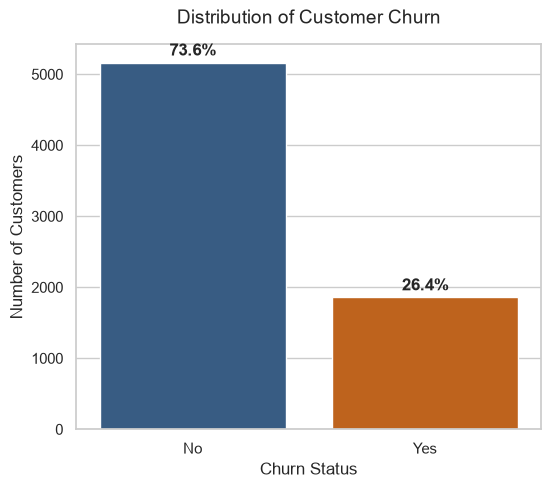

In [14]:
plt.figure(figsize=(6, 5))
ax = sns.countplot(x="Churn", data=df, hue="Churn", legend=False, palette=["#2b5c8f", "#d95f02"])
plt.title("Distribution of Customer Churn", fontsize=14, pad=15)
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

# Add percentage labels on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x_coord = p.get_x() + p.get_width() / 2 - 0.1
    y_coord = p.get_height() + 100
    ax.annotate(percentage, (x_coord, y_coord), fontsize=12, fontweight='bold')

plt.savefig(os.path.join(figures_dir, "01_churn_distribution.png"), bbox_inches='tight', dpi=150)
plt.show()

### Churn Distribution Takeaways:
- **Class Imbalance:** The target variable `Churn` exhibits a strong class imbalance: ~73.5% of customers do not churn (`No`), while ~26.5% do churn (`Yes`).
- **Implications for Metric Selection:** Standard accuracy is a misleading metric here. A dummy classifier predicting "No Churn" for all customers would achieve 73.5% accuracy but would be completely useless in detecting churn. 
- **Need for Balancing:** To build a robust model, we will need to handle this imbalance (using class weights or SMOTE in Phase 6).
- **Evaluation Focus:** Metrics like ROC-AUC, Recall (catching actual churners), Precision (not wasting retention offers on loyal customers), and F1-score will be much more important than raw Accuracy.

### 2. Categorical Features vs. Churn
Let's look at how categorical features relate to customer churn. We plot percentages to make categories comparable.

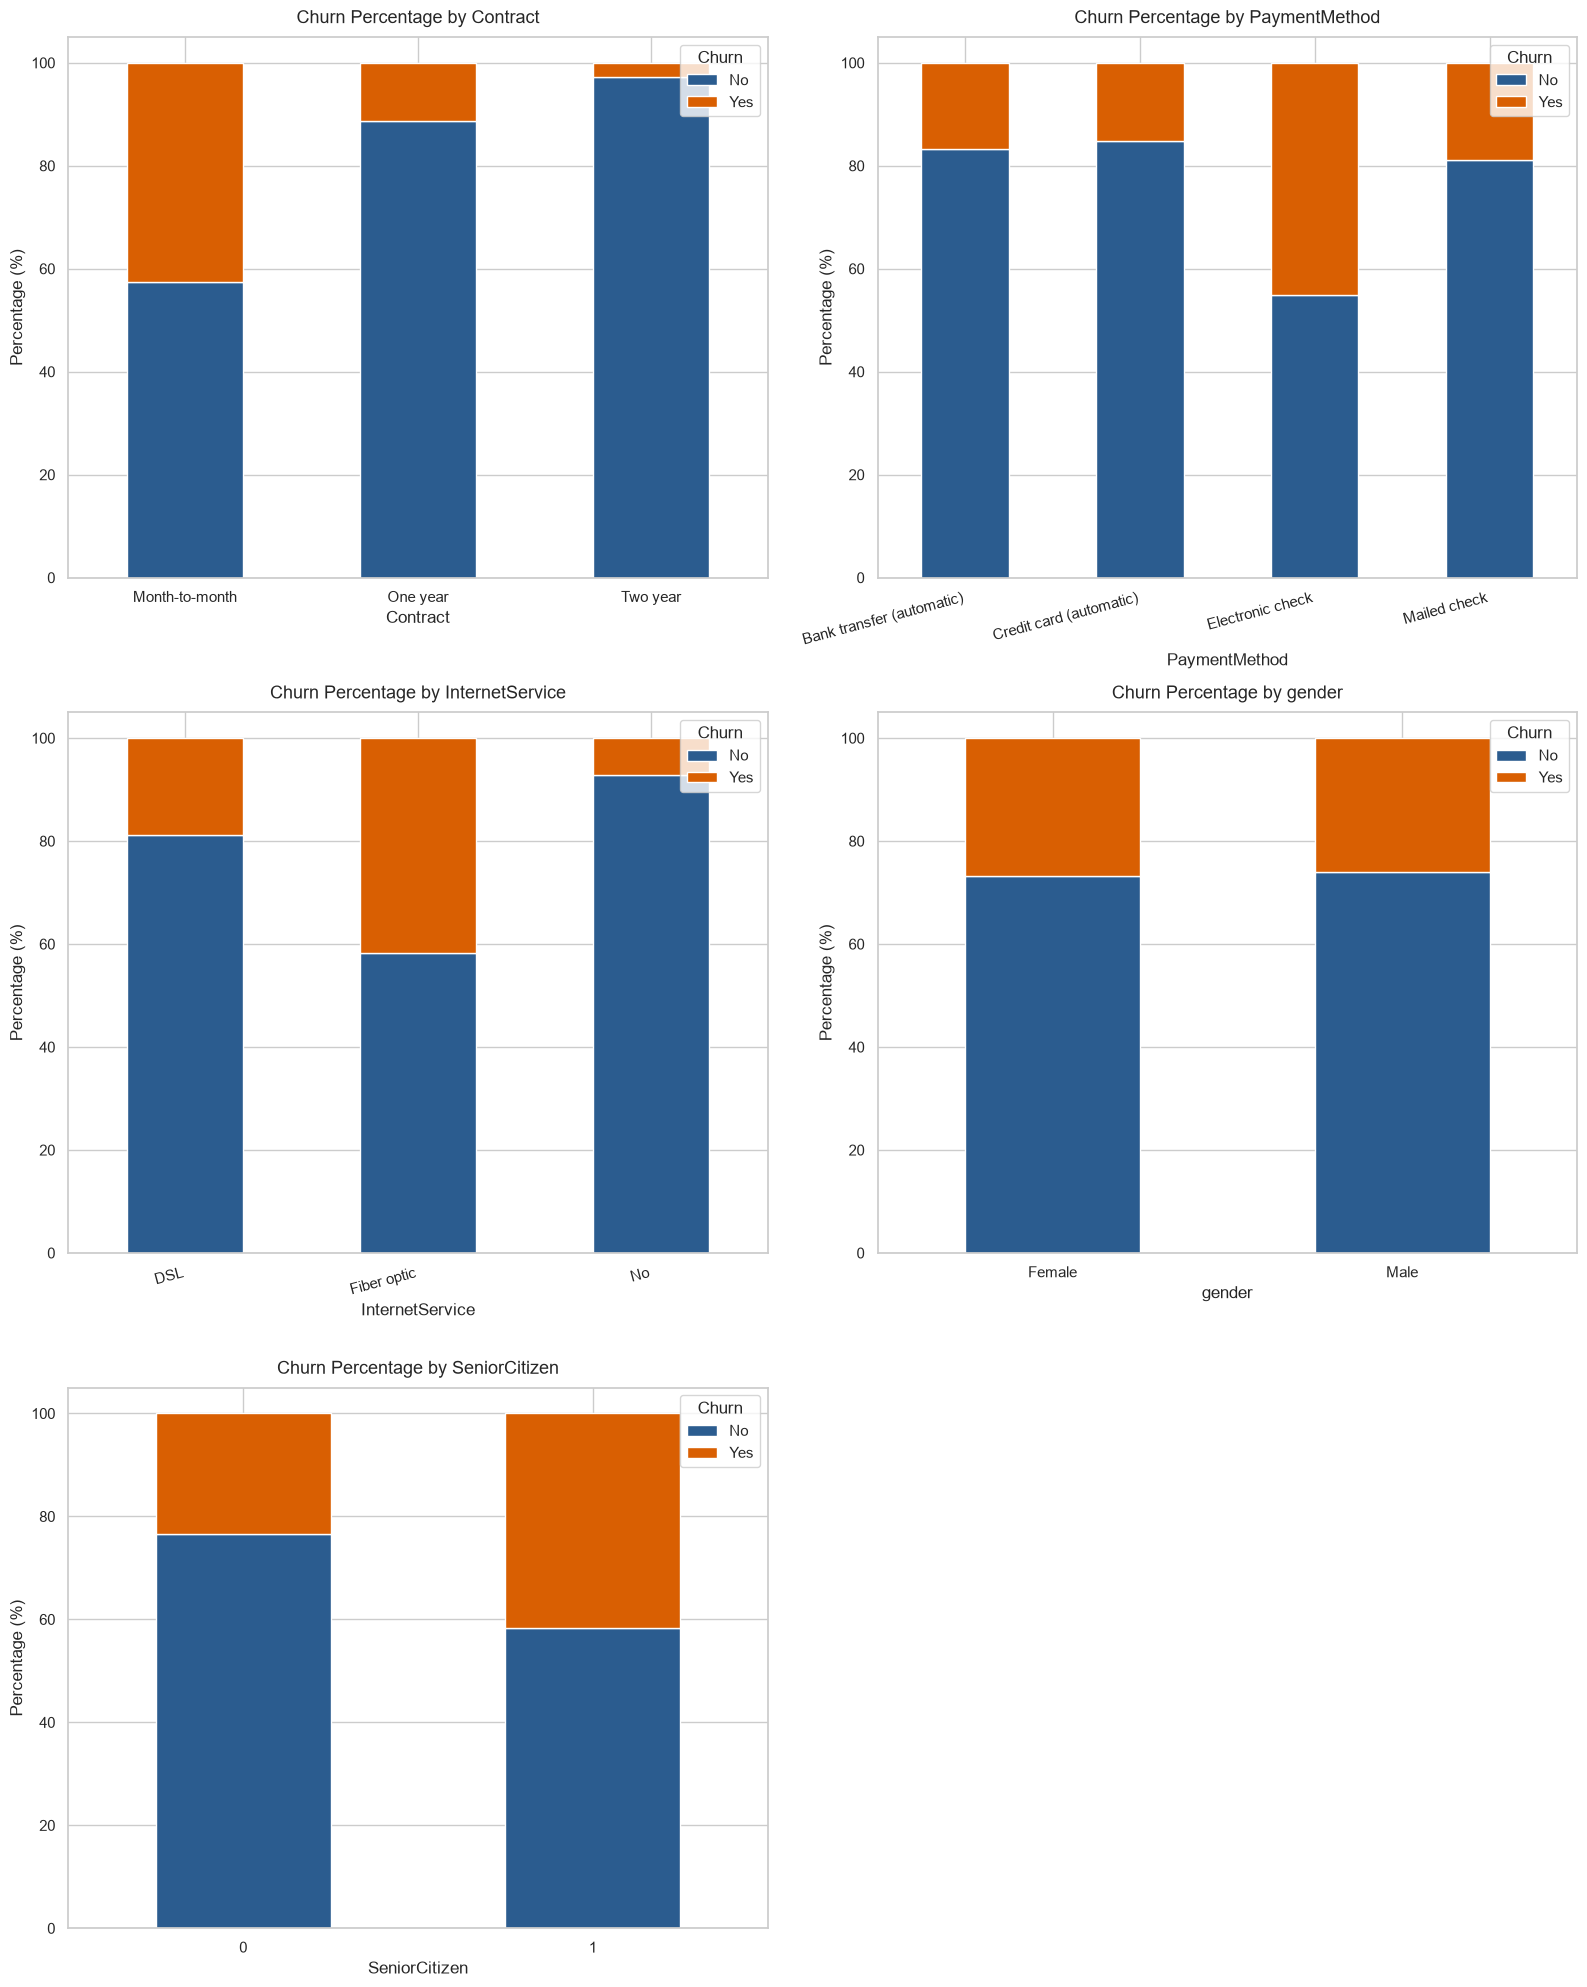

In [15]:
cat_cols = ["Contract", "PaymentMethod", "InternetService", "gender", "SeniorCitizen"]

fig, axes = plt.subplots(3, 2, figsize=(16, 20))
axes = axes.flatten()  # Flatten to a 1D list of length 6

for i, col in enumerate(cat_cols):
    # Calculate percentages for stack bar chart
    cross_tab = pd.crosstab(df[col], df["Churn"], normalize="index") * 100
    
    # Plot stacked bar chart
    cross_tab.plot(kind='bar', stacked=True, color=["#2b5c8f", "#d95f02"], ax=axes[i], rot=0)
    axes[i].set_title(f"Churn Percentage by {col}", fontsize=13, pad=10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Percentage (%)")
    axes[i].legend(title="Churn", loc='upper right')
    
    # Rotate labels if they overlap
    if col in ["PaymentMethod", "InternetService"]:
        axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=15, ha='right')

# Hide the 6th subplot axis since we only have 5 categories
axes[5].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "02_churn_vs_categoricals.png"), bbox_inches='tight', dpi=150)
plt.show()

### Categorical Features Takeaways:
- **Contract Type Impact:** Month-to-month contract customers churn at an extremely high rate (~43%), whereas customers on one-year (~11%) or two-year (~3%) contracts are very stable. Getting customers onto long-term contracts is a key business recommendation.
- **Payment Method Risk:** Customers paying via `Electronic check` show a disproportionately high churn rate (~45%), while automatic payment methods (credit cards, bank transfers) show much lower churn (~15-16%). Electronic checks might have manual billing friction or higher transaction failures.
- **Internet Service Risk:** Fiber optic internet customers churn at a high rate (~42%) compared to DSL (~19%) or No Internet (~7%). This might indicate technical issues, pricing complaints, or intense competitive offers in the high-speed tier.
- **Gender Insignificance:** Gender plays almost no role in churn, as the churn rates for both Male and Female customers are virtually identical (~26%).
- **Senior Citizen Vulnerability:** Senior citizens churn at a higher rate (~42%) than younger customers (~24%). Younger customers may have family plans or less financial sensitivity, whereas senior citizens might be on fixed incomes.

### 3. Numerical Features vs. Churn (Bivariate Boxplots)
We investigate how `tenure` and `MonthlyCharges` differ between churners and non-churners using boxplots.

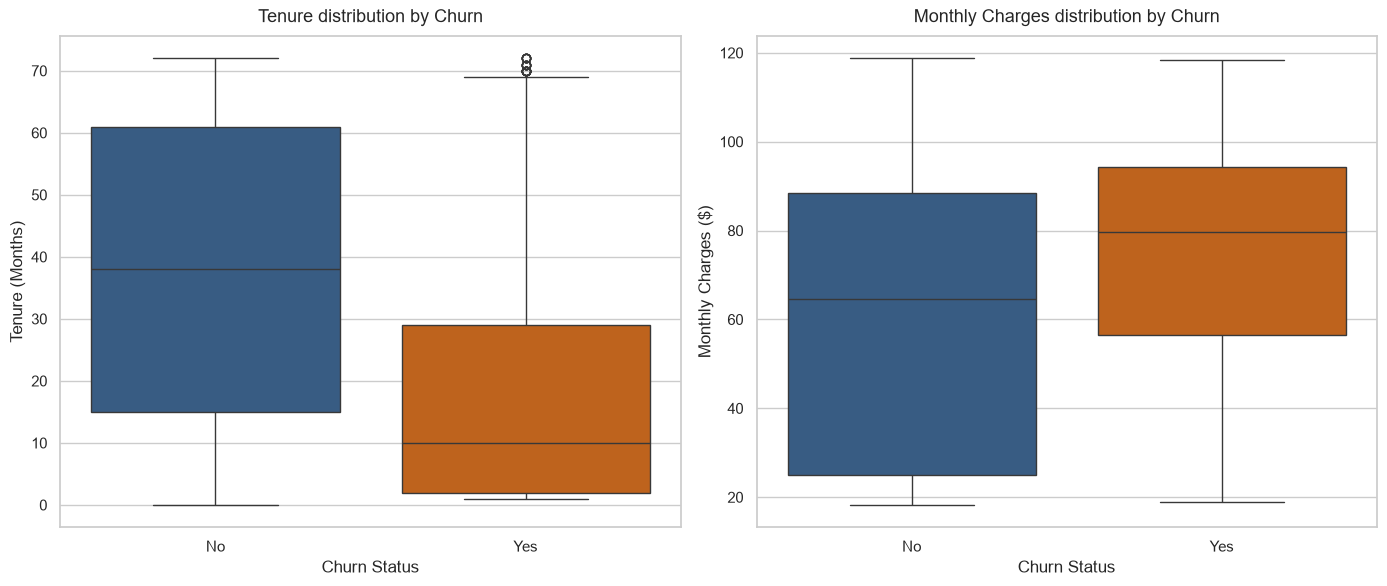

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(x="Churn", y="tenure", data=df, hue="Churn", legend=False, palette=["#2b5c8f", "#d95f02"], ax=axes[0])
axes[0].set_title("Tenure distribution by Churn", fontsize=13, pad=10)
axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Tenure (Months)")

sns.boxplot(x="Churn", y="MonthlyCharges", data=df, hue="Churn", legend=False, palette=["#2b5c8f", "#d95f02"], ax=axes[1])
axes[1].set_title("Monthly Charges distribution by Churn", fontsize=13, pad=10)
axes[1].set_xlabel("Churn Status")
axes[1].set_ylabel("Monthly Charges ($)")

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "03_numerical_vs_churn.png"), bbox_inches='tight', dpi=150)
plt.show()

### Bivariate Numerical Takeaways:
- **Critical Tenure Gap:** Customers who churn (`Yes`) have a much lower median tenure (~10 months) compared to those who stay (~38 months). This indicates churn happens early, typically in the first year of contract lifecycle.
- **Higher Costs Drive Churn:** Customers who churn have a higher median monthly charge (~$80) compared to retained customers (~$65). This indicates high prices are a significant churn driver.
- **The "Onboarding Danger Zone":** The first 12 months represent a critical onboarding phase. If a customer survives the first year, their probability of churning drops significantly.
- **Price Sensitivity:** High monthly costs are correlated with higher churn. We should investigate if this is tied to specific service bundles (like fiber optic + add-on packages).
- **Low-Cost Retention:** Retained customers have a wider distribution of monthly charges, including many low-paying customers who are highly loyal.

### 4. Distributions of Numerical Columns (Univariate Histograms)
Let's see the distributions of `tenure`, `MonthlyCharges`, and `TotalCharges` across the entire customer base.

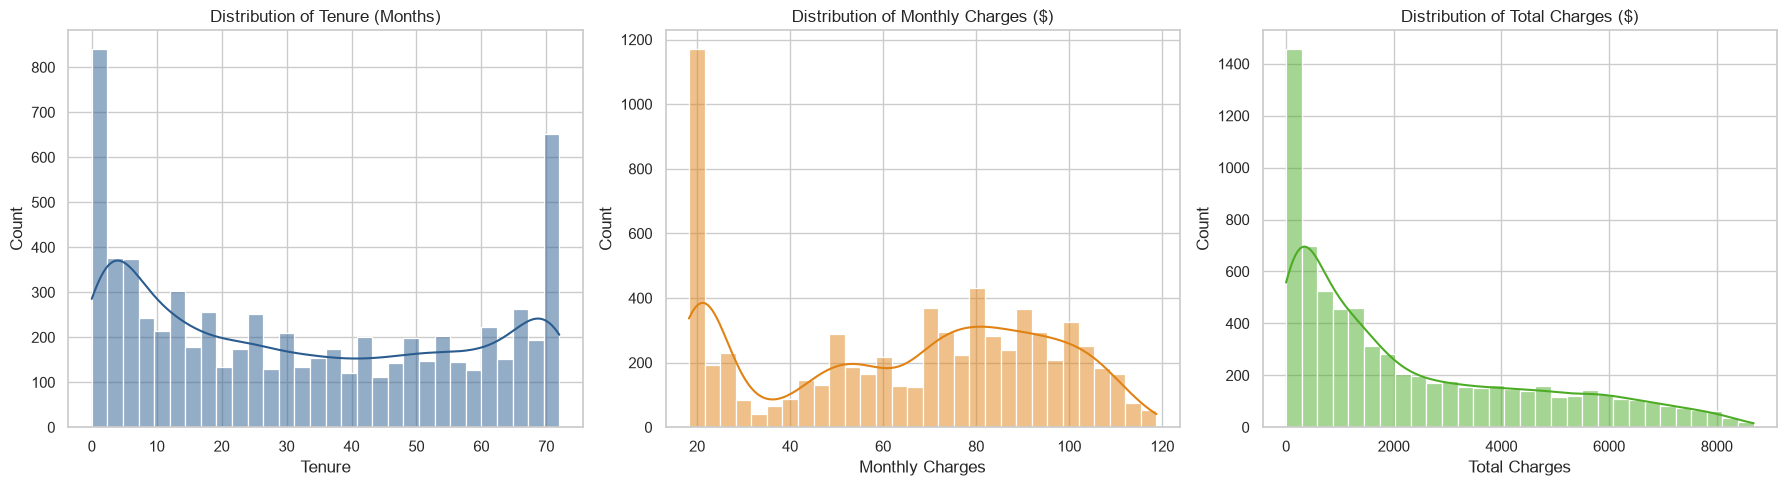

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["tenure"], kde=True, color="#2b5c8f", ax=axes[0], bins=30)
axes[0].set_title("Distribution of Tenure (Months)")
axes[0].set_xlabel("Tenure")

sns.histplot(df["MonthlyCharges"], kde=True, color="#e08214", ax=axes[1], bins=30)
axes[1].set_title("Distribution of Monthly Charges ($)")
axes[1].set_xlabel("Monthly Charges")

sns.histplot(df["TotalCharges"], kde=True, color="#4dac26", ax=axes[2], bins=30)
axes[2].set_title("Distribution of Total Charges ($)")
axes[2].set_xlabel("Total Charges")

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "04_numerical_distributions.png"), bbox_inches='tight', dpi=150)
plt.show()

### Distribution Takeaways:
- **U-Shaped Tenure:** The `tenure` distribution is U-shaped: there is a huge cluster of new customers (1-5 months) and another large cluster of highly loyal customers (60-72 months). This indicates customer lifetime is polarized.
- **Bimodal Monthly Charges:** The `MonthlyCharges` distribution is bimodal. There is a sharp spike around $20 (representing basic plan/no-internet customers) and a broad hump between $70-$100 (representing broadband/premium-service customers).
- **Right-Skewed Total Charges:** The `TotalCharges` distribution is strongly right-skewed, showing that the majority of customers have lower total lifetime charges, with a long tail of high-value accounts.
- **The Onboarding Challenge:** The high count of low-tenure customers reinforces that customer acquisition is active, but early-stage retention is the primary business bottleneck.
- **Revenue Skewness:** The long tail of `TotalCharges` indicates that a small fraction of customers represent a large share of lifetime revenue, making their retention critically important.

### 5. Verification of Structural Correlation (Scatter Plot)
Let's plot `tenure` vs `TotalCharges`, colored by `Churn` to visualize the relationship $TotalCharges \approx tenure \times MonthlyCharges$.

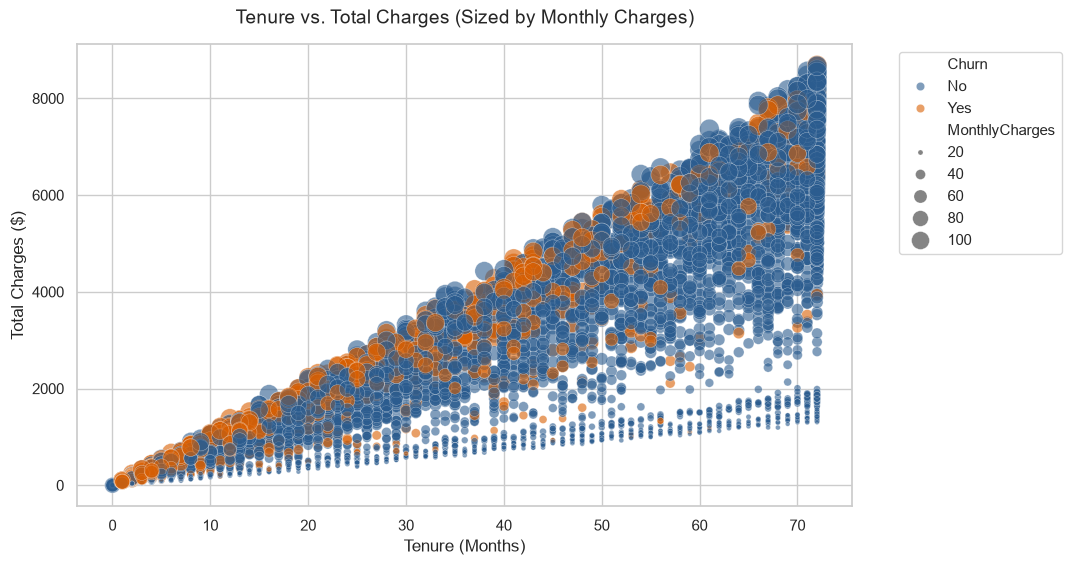

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x="tenure", y="TotalCharges", hue="Churn", size="MonthlyCharges", 
                sizes=(10, 200), alpha=0.6, palette=["#2b5c8f", "#d95f02"], data=df)
plt.title("Tenure vs. Total Charges (Sized by Monthly Charges)", fontsize=14, pad=15)
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges ($)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig(os.path.join(figures_dir, "05_tenure_vs_totalcharges.png"), bbox_inches='tight', dpi=150)
plt.show()

### Structural Scatter Plot Takeaways:
- **Linear Relationship & Fan Effect:** The scatter plot shows a clear linear fan-like shape. For any given tenure, the range of `TotalCharges` is bounded by the monthly subscription rates. The slope of each line represents the customer's monthly bill.
- **Visualizing the Churn Zone (Orange):** Churners (orange points) are heavily concentrated in the bottom-left corner (low tenure) and along the upper bounds of the fan (high Monthly Charges, indicated by larger dot sizes). 
- **Visualizing the Loyalty Zone (Blue):** Retained customers (blue points) dominate the high-tenure right side of the plot.
- **Implicit Multi-collinearity:** This plot confirms that `TotalCharges` is a mathematical function of `tenure` and `MonthlyCharges`. Including all three in linear models will cause multicollinearity. We will verify this with VIF in Phase 4.
- **High-Margin Risk:** The upper edge of the fan (large dots representing expensive packages) shows a heavy concentration of orange churn dots, illustrating that high-paying accounts are high-risk.

### 6. Correlation Analysis
Let's look at the correlation coefficients between our numeric variables (including the binary Target variable `Churn` mapped to 0/1).

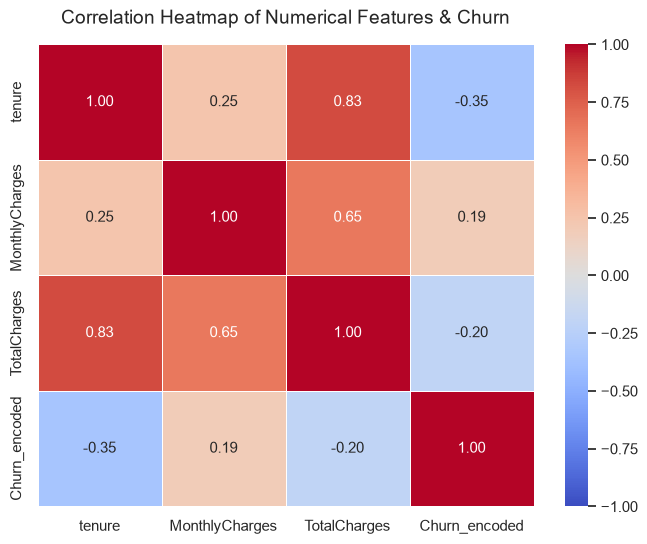

In [19]:
# Encode Churn to 0/1 for correlation analysis
df_corr = df[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
df_corr["Churn_encoded"] = df["Churn"].map({"Yes": 1, "No": 0})

# Compute correlation matrix
corr_matrix = df_corr.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Features & Churn", fontsize=14, pad=15)

plt.savefig(os.path.join(figures_dir, "06_correlation_heatmap.png"), bbox_inches='tight', dpi=150)
plt.show()

### Correlation Takeaways:
- **Strong Multicollinearity:** `TotalCharges` is highly correlated with `tenure` (0.83) and moderately correlated with `MonthlyCharges` (0.65). This is mathematically expected since `TotalCharges` is a product of both.
- **Tenure is the Strongest Retainer:** `tenure` has a strong negative correlation with Churn (-0.35). As tenure increases, churn probability decreases.
- **Cost is a Churn Driver:** `MonthlyCharges` is positively correlated with Churn (0.19). Higher monthly bills drive customers to churn.
- **Total Charges Ambiguity:** `TotalCharges` shows a weak negative correlation with churn (-0.20). This is a composite effect: long-term customers stay, but they also accumulate high total charges. This highlights why univariate correlation can be misleading without controlling for tenure.
- **Feature Selection Strategy:** Because of the strong correlation between `TotalCharges` and `tenure`/`MonthlyCharges`, linear models (like Logistic Regression) will face coefficients instability. We must be prepared to address this in Phase 4.

## 7. Save Cleaned Dataset (Confirming Final State)

We save the final cleaned dataset with the modifications and verify its final structure.

In [20]:
processed_path = os.path.join("..", "data", "processed", "01_cleaned_data.csv")

try:
    df.to_csv(processed_path, index=False)
    print(f"Cleaned dataset saved successfully to {processed_path}")
except PermissionError:
    print(f"PermissionError: Could not overwrite {processed_path}. The file might be open in another application.")
    if os.path.exists(processed_path):
        existing_df = pd.read_csv(processed_path)
        print(f"Existing file shape: {existing_df.shape}. Matches current shape: {df.shape == existing_df.shape}")

print(f"Data Type of TotalCharges: {df['TotalCharges'].dtype}")
print(f"Shape of dataset: {df.shape}")
print(f"Nulls count: {df.isnull().sum().sum()}")

PermissionError: Could not overwrite ..\data\processed\01_cleaned_data.csv. The file might be open in another application.
Existing file shape: (7021, 20). Matches current shape: True
Data Type of TotalCharges: float64
Shape of dataset: (7021, 20)
Nulls count: 0
